# Evolution of the ten most frequently edited skills

The first notebook showed that gitskills dataset srotes only the summary of the changes, it does not store the changes itself. To study the evolution of the changes we need to enrich the information with the history of changes for each file.

Here we use ten representative skills with the highest `commit_count` among th files with collected history. The query is the one used in the exploration notebook, with `repo_full_name` and `content` added so we can identify and check each file.

The [collection script](../scripts/collect_gitskills_history.py) retrieves the github versions up to each file's `last_commit_at` and writes `data/gitskills/evolution_pilot.json`. Run it from the thesis folder to refresh the file.

## Select skills from GitSkills

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

db = Path("../data/gitskills/agent_skills_sample.db")
data = Path("../data/gitskills/evolution_pilot.json")
if not db.exists():
    db = Path("data/gitskills/agent_skills_sample.db")
    data = Path("data/gitskills/evolution_pilot.json")

with sqlite3.connect(db) as connection:
    selected = pd.read_sql_query("""
        SELECT repo_full_name, name, path, first_commit_at, last_commit_at,
               commit_count, content
        FROM artifacts
        WHERE dedup_primary = 1 AND history_fetched = 1 AND commit_count > 1
        ORDER BY commit_count DESC
        LIMIT 10
    """, connection)
selected.drop(columns="content")

,repo_full_name,name,path,first_commit_at,last_commit_at,commit_count
0,ericpzh/AC27LevelEditor,None,.claude/skills/ac27-level-editor/SKILL.md,2026-06-01T23:02:10Z,2026-07-23T06:35:00Z,70
1,daiki-beppu/youtube-automation,loop-video,.claude/skills/loop-video/SKILL.md,2026-04-09T08:06:48Z,2026-07-22T14:08:09Z,40
2,Wilder1222/superomni,plan-review,skills/plan-review/SKILL.md,2026-03-25T04:06:32Z,2026-06-30T02:53:40Z,39
3,duc01226/EasyPlatform,refine,.claude/skills/refine/SKILL.md,2026-01-19T14:27:57Z,2026-06-04T08:22:51Z,32
4,gabb-software/gabb-cli,gabb-code-navigation,.claude/skills/gabb/SKILL.md,2025-12-17T13:20:01Z,2026-04-02T08:06:39Z,31
5,Chris-Graffagnino/creance,next-task,.claude/skills/next-task/SKILL.md,2026-06-12T13:10:45Z,2026-07-11T00:09:12Z,28
6,autonomys/openclaw-skills,auto-respawn,autonomys/auto-respawn/SKILL.md,2026-02-25T12:03:55Z,2026-07-01T09:34:38Z,26
7,Q00/ouroboros,run,skills/run/SKILL.md,2026-02-20T07:26:36Z,2026-07-17T14:55:21Z,26
8,keturk/datrix,None,claude-config/.claude/skills/operationalize-de...,2026-05-09T22:53:28Z,2026-07-14T08:09:14Z,25
9,hunknownz/codex-speak,codex-speak,skills/codex-speak/SKILL.md,2026-05-30T04:28:16Z,2026-06-13T02:40:24Z,23


## Load the GitHub versions

Each JSON object contains one version of one skill. We have to do wto check: whether we retrieved the same number of commits as gitskills recorded, and if the final GitHub text matches the text in GitSkills.

In [2]:
history = pd.read_json(data, convert_dates=["committed_at"])
history = history.sort_values(["repo_full_name", "path", "committed_at"]).reset_index(drop=True)

## Check the collected history

In [3]:
coverage = history.groupby(["repo_full_name", "path"], as_index=False).agg(
    retrieved=("commit_sha", "size"),
    available_text=("content", "count"),
    latest_text=("content", "last")
)
coverage = selected.merge(coverage, on=["repo_full_name", "path"])
coverage["same_count"] = coverage["retrieved"] == coverage["commit_count"]
coverage["same_text"] = coverage["latest_text"] == coverage["content"]
coverage[["name", "repo_full_name", "commit_count", "retrieved", "available_text", "same_count", "same_text"]]

,name,repo_full_name,commit_count,retrieved,available_text,same_count,same_text
0,None,ericpzh/AC27LevelEditor,70,70,70,True,False
1,loop-video,daiki-beppu/youtube-automation,40,40,40,True,False
2,plan-review,Wilder1222/superomni,39,39,39,True,True
3,refine,duc01226/EasyPlatform,32,31,30,False,False
4,gabb-code-navigation,gabb-software/gabb-cli,31,31,31,True,True
5,next-task,Chris-Graffagnino/creance,28,28,28,True,True
6,auto-respawn,autonomys/openclaw-skills,26,26,26,True,True
7,run,Q00/ouroboros,26,26,26,True,True
8,None,keturk/datrix,25,25,25,True,True
9,codex-speak,hunknownz/codex-speak,23,23,23,True,True


A mismatch matters when interpreting the snapshot: the GitSkills text and the last version returned by GitHub may come from different collection moments. If a version has no text at this path, its file length is unavailable, but the GitHub API can still provide line-change counts.

## Changes in each commit

In [4]:
changes = history.copy()
changes["skill"] = changes["name"].fillna(changes["path"].str.split("/").str[-2])
changes["lines"] = changes["content"].map(
    lambda text: len(text.splitlines()) if isinstance(text, str) else None
)
changes["added"] = changes["additions"]
changes["removed"] = changes["deletions"]
changes["delta"] = changes["added"] - changes["removed"]

edits = changes.sort_values("added", ascending=False)
edits[["skill", "committed_at", "added", "removed", "delta", "message"]].head(12)

,skill,committed_at,added,removed,delta,message
75,plan-review,2026-04-09 02:42:07+00:00,538,34,504,Refactor code structure for improved readabili...
166,refine,2026-01-28 08:39:10+00:00,453,9,444,refactor(claude): consolidate skills with inli...
162,refine,2026-01-23 04:34:32+00:00,423,66,357,feat(claude): enhance BA skills and add web-de...
314,operationalize-design,2026-05-09 22:53:28+00:00,379,0,379,Update datetime examples and test status repor...
168,refine,2026-03-01 01:00:43+00:00,344,0,344,refactor(claude): adapt all BravoSUITE referen...
190,ac27-level-editor,2026-06-01 23:02:10+00:00,328,0,328,"refactor: migrate skills to .claude/skills, ad..."
213,ac27-level-editor,2026-06-14 04:13:28+00:00,323,15,308,@\ndocs: update repo skill + README for v1.1.3...
270,gabb-code-navigation,2025-12-22 10:44:52+00:00,297,53,244,fix: use --workspace instead of --root in MCP ...
169,refine,2026-03-10 06:26:33+00:00,290,27,263,"feat(claude): consolidate AI tooling, fix dang..."
208,ac27-level-editor,2026-06-11 07:01:41+00:00,287,21,266,"@\nv1.1.2 — StarMap overlay, State=5 approach ..."


Added and removed lines come from the GitHub API for each `SKILL.md` commit. `delta` is added minus removed; it shows whether the file grew or shrank in that commit.

## File length over time

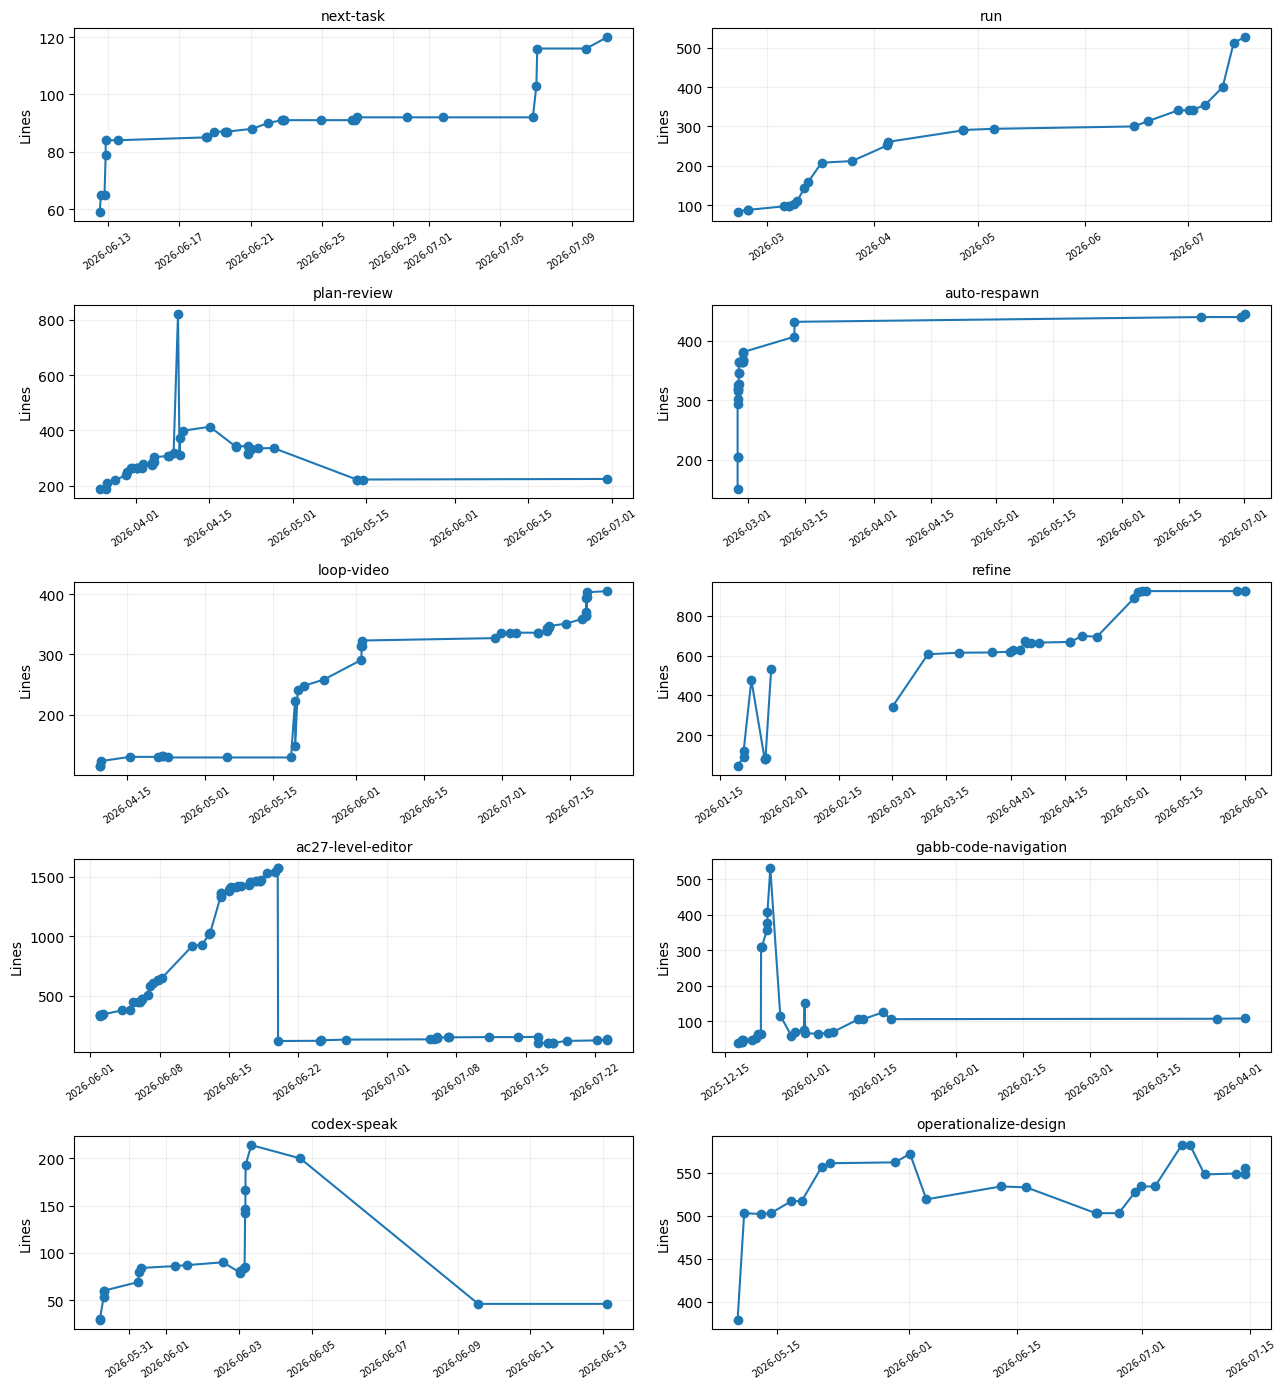

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(13, 14))
for ax, (skill, group) in zip(axes.flat, changes.groupby("skill", sort=False)):
    ax.plot(group["committed_at"], group["lines"], marker="o", linewidth=1.5)
    ax.set_title(skill, fontsize=10)
    ax.set_ylabel("Lines")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelrotation=35, labelsize=7)
fig.tight_layout()
plt.show()

## What we can conclude

This is a purposive set of the most frequently edited files in the sample, the dataset itself does not contain the file history but we can use github api to "enrich" the dataset to have this information. It is useful for the next steps that's to make a classification of change types.

Next steps:
 - Try to classify the change types in skill files